# LAB3 - Phần 2 - Bài 2

## Câu 1

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # tránh cảnh báo memory leak của KMeans trên Windows

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn import metrics

import seaborn as sns
import plotly as py
import plotly.graph_objs as go
import matplotlib.pyplot as plt
%matplotlib inline

py.offline.init_notebook_mode(connected=True)

In [2]:
data = pd.read_csv('./Dataset/Mall_Customers.csv')
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Đặng Phan Duy - 6451071010

In [3]:
print("Shape:", data.shape)
data.info()

Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


Đặng Phan Duy - 6451071010

In [4]:
# Thống kê các thông tin cơ bản
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Đặng Phan Duy - 6451071010

In [5]:
# Kiểm tra dữ liệu bị thiếu
data.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Đặng Phan Duy - 6451071010

Nhận xét: bộ dữ liệu có 200 mẫu, 5 thuộc tính và không có giá trị bị thiếu ở cột nào nên không cần xử lý. Đoạn code dưới đây vẫn xóa các dòng thiếu dữ liệu (nếu có) để đảm bảo an toàn.

In [6]:
# Xử lý dữ liệu bị thiếu: xóa các dòng có giá trị trống
data = data.dropna()
print("Shape sau khi xử lý dữ liệu thiếu:", data.shape)

Shape sau khi xử lý dữ liệu thiếu: (200, 5)


Đặng Phan Duy - 6451071010

## Câu 2

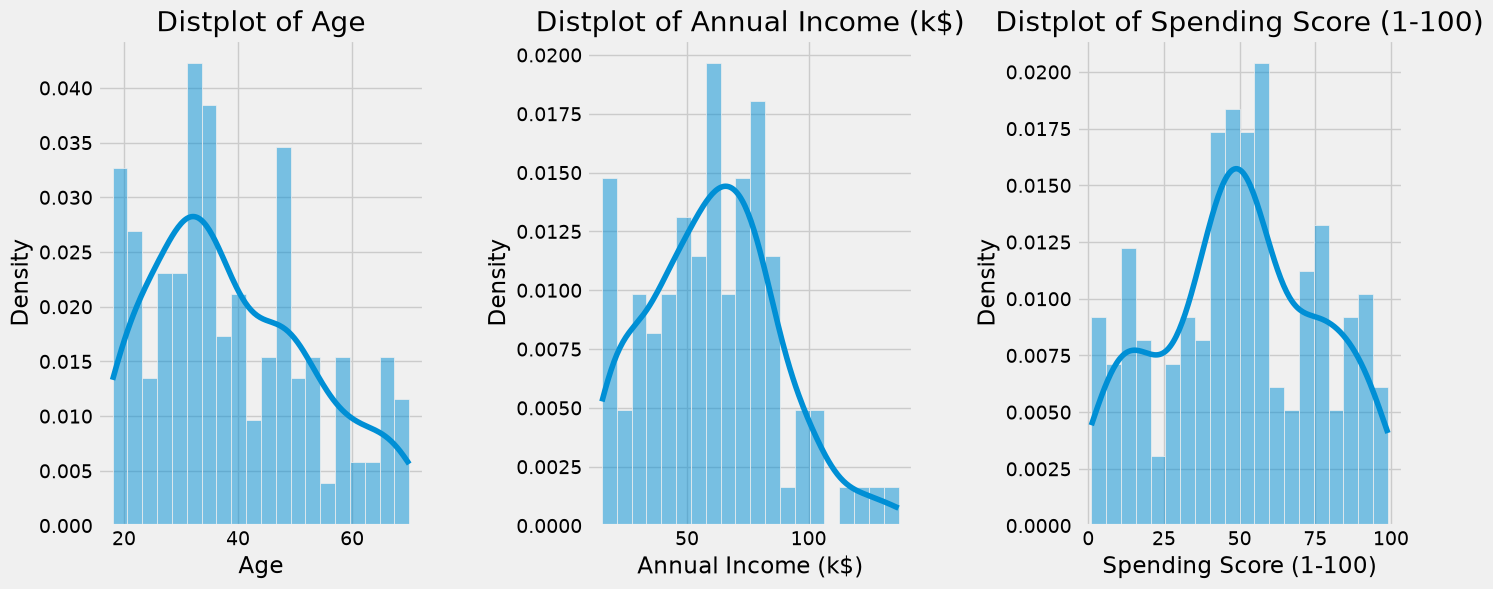

In [7]:
plt.style.use('fivethirtyeight')
plt.figure(1, figsize = (15, 6))
n = 0
for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace = 0.5, wspace = 0.5)
    sns.histplot(data[x], bins = 20, kde = True, stat = 'density')
    plt.title('Distplot of {}'.format(x))
plt.show()

Đặng Phan Duy - 6451071010

## Câu 3

Gender
Female    112
Male       88
Name: count, dtype: int64


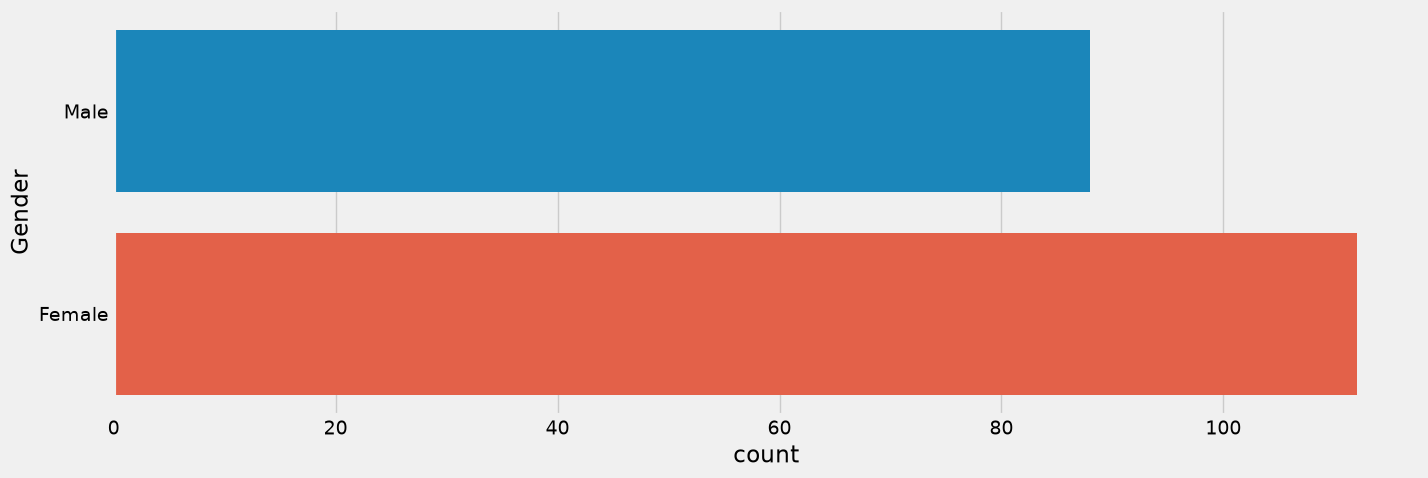

In [8]:
print(data['Gender'].value_counts())

plt.figure(1, figsize = (15, 5))
sns.countplot(y = 'Gender', data = data, hue = 'Gender')
plt.show()

Đặng Phan Duy - 6451071010

## Câu 4

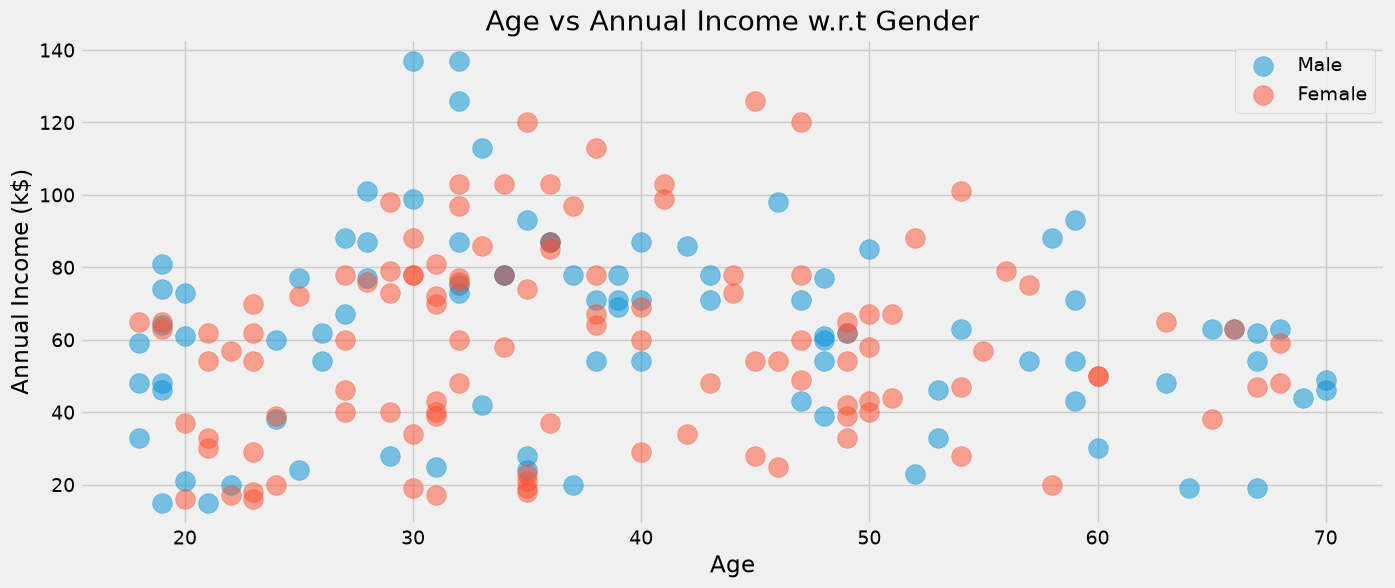

In [9]:
plt.figure(1, figsize = (15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x = 'Age', y = 'Annual Income (k$)', data = data[data['Gender'] == gender],
                s = 200, alpha = 0.5, label = gender)
plt.xlabel('Age'), plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income w.r.t Gender')
plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

## Câu 5

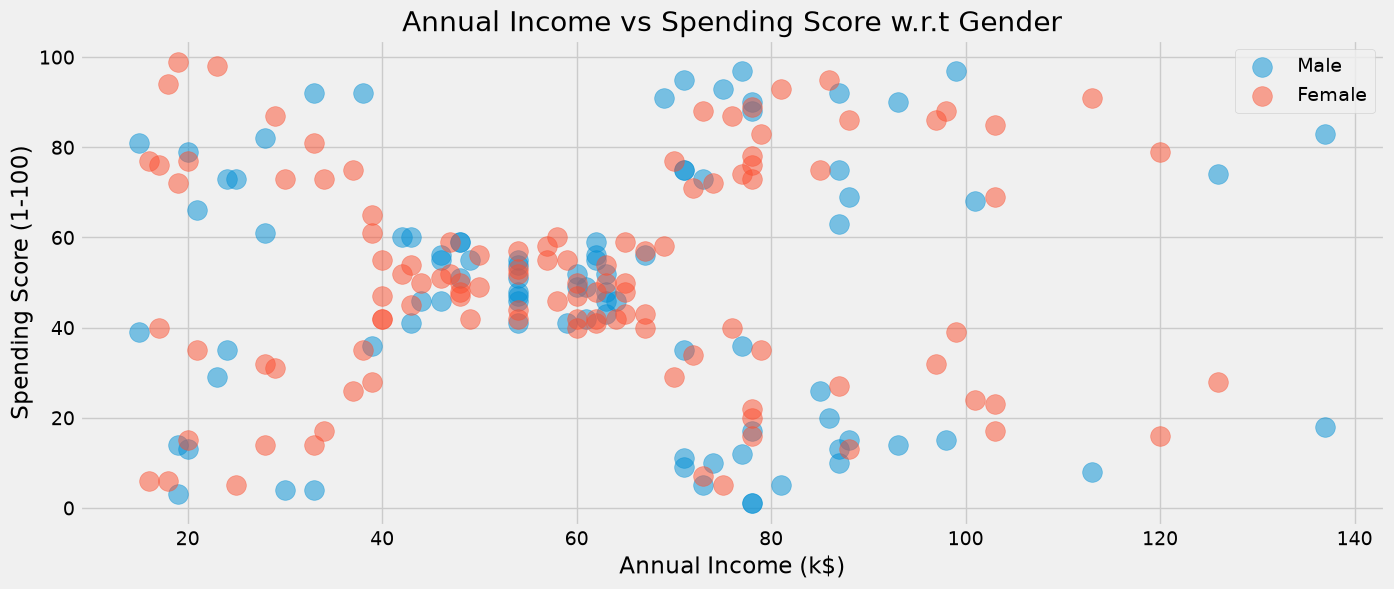

In [10]:
plt.figure(1, figsize = (15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x = 'Annual Income (k$)', y = 'Spending Score (1-100)', data = data[data['Gender'] == gender],
                s = 200, alpha = 0.5, label = gender)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

## Câu 6

In [11]:
X1 = data[['Age' , 'Spending Score (1-100)']].iloc[: , :].values
inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters = n, init='random', n_init=10, random_state=42)
    algorithm.fit(X1)
    inertia.append(algorithm.inertia_)
print(np.round(inertia, 2))

[171535.5   75949.16  45840.68  28165.58  23839.26  19577.26  15514.19
  13024.1   11823.56  10336.2 ]


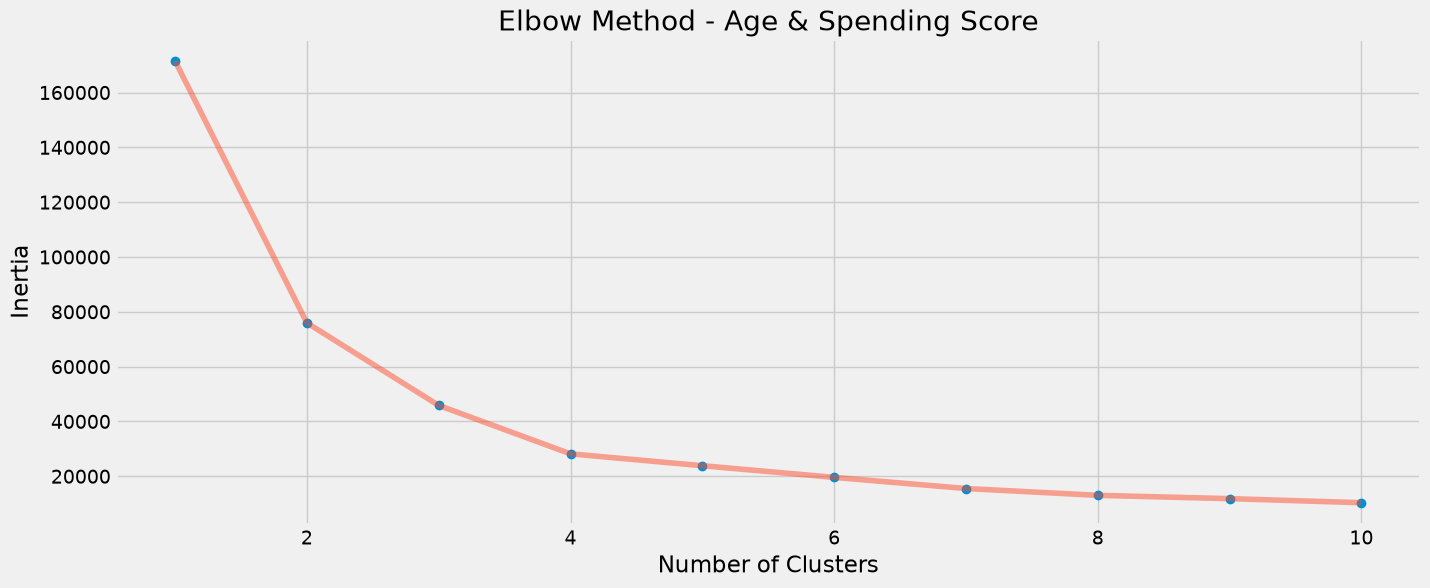

In [12]:
plt.figure(1, figsize = (15, 6))
plt.plot(np.arange(1 , 11), inertia, 'o')
plt.plot(np.arange(1 , 11), inertia, '-', alpha = 0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method - Age & Spending Score')
plt.show()

Đặng Phan Duy - 6451071010

Nhận xét: inertia giảm mạnh từ k = 1 đến k = 4, sau k = 4 đường cong gần như nằm ngang (giảm chậm). Vị trí khuỷu tay là k = 4 nên chọn số cụm k = 4.

In [13]:
algorithm = KMeans(n_clusters = 4, init='random', n_init=10, random_state=42)
algorithm.fit(X1)
labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_
print("Centroids:\n", centroids1)

Centroids:
 [[55.70833333 48.22916667]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]
 [30.1754386  82.35087719]]


Đặng Phan Duy - 6451071010

## Câu 7

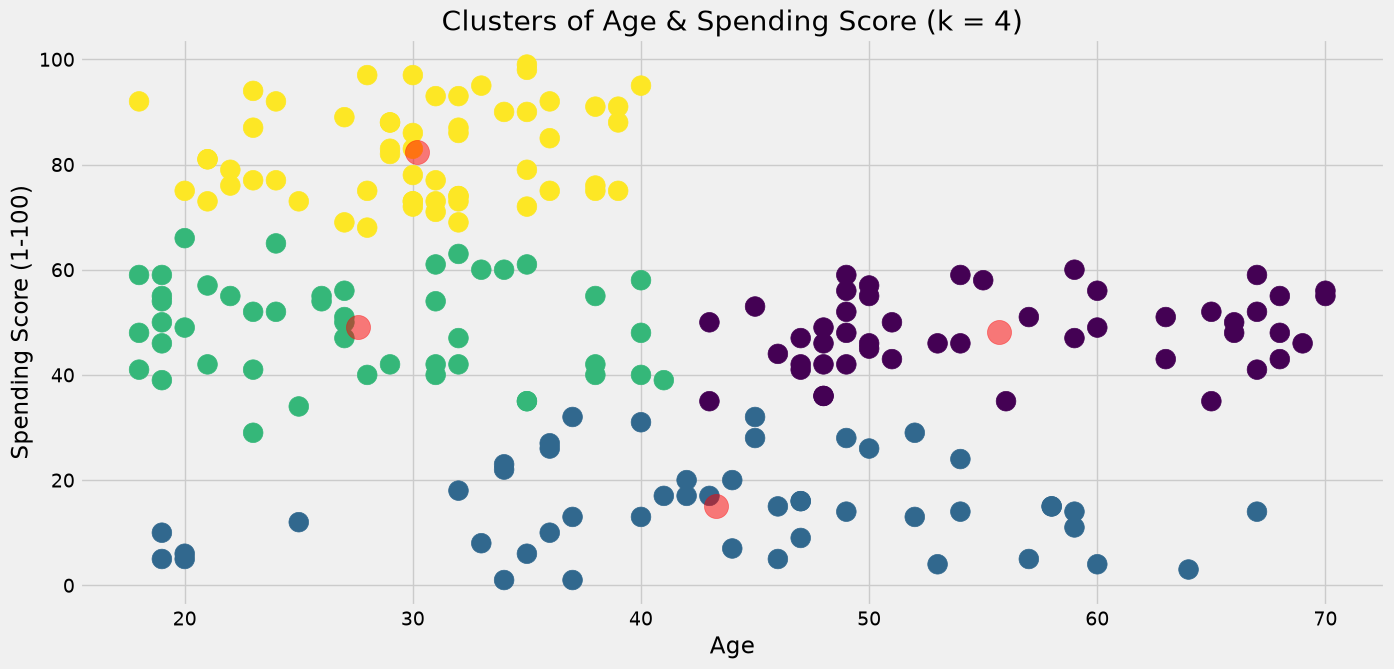

In [14]:
plt.figure(1 , figsize = (15, 7) )
plt.clf()
plt.scatter(x = 'Age', y = 'Spending Score (1-100)', data = data, c = labels1,
            s = 200 )
plt.scatter(x = centroids1[: , 0], y =  centroids1[: , 1], s = 300, c = 'red', alpha = 0.5)
plt.ylabel('Spending Score (1-100)'), plt.xlabel('Age')
plt.title('Clusters of Age & Spending Score (k = 4)')
plt.show()

Đặng Phan Duy - 6451071010

## Câu 8

In [15]:
silhouette1 = metrics.silhouette_score(X1, labels1, metric = 'euclidean')
print("Silhouette coefficient (Age & Spending Score):", silhouette1)

Silhouette coefficient (Age & Spending Score): 0.49973941540141753


Đặng Phan Duy - 6451071010

Nhận xét: hệ số Silhouette ≈ 0.50 (> 0), các cụm được phân tách tương đối rõ, phần lớn các điểm gần với cụm của mình hơn các cụm khác. Tuy nhiên vẫn còn một số điểm nằm ở vùng giáp ranh giữa các cụm (ví dụ giữa nhóm trẻ tuổi có điểm mua sắm trung bình và nhóm trung niên), nên chất lượng gom cụm ở mức khá.

## Câu 9

### Gom cụm theo Thu nhập hằng năm và Số điểm mua sắm

In [16]:
X2 = data[['Annual Income (k$)' , 'Spending Score (1-100)']].iloc[: , :].values
inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters = n, init='random', n_init=10, random_state=42)
    algorithm.fit(X2)
    inertia.append(algorithm.inertia_)
print(np.round(inertia, 2))

[269981.28 181363.6  106348.37  73679.79  44448.46  37564.94  31280.9
  25063.65  21826.94  20298.39]


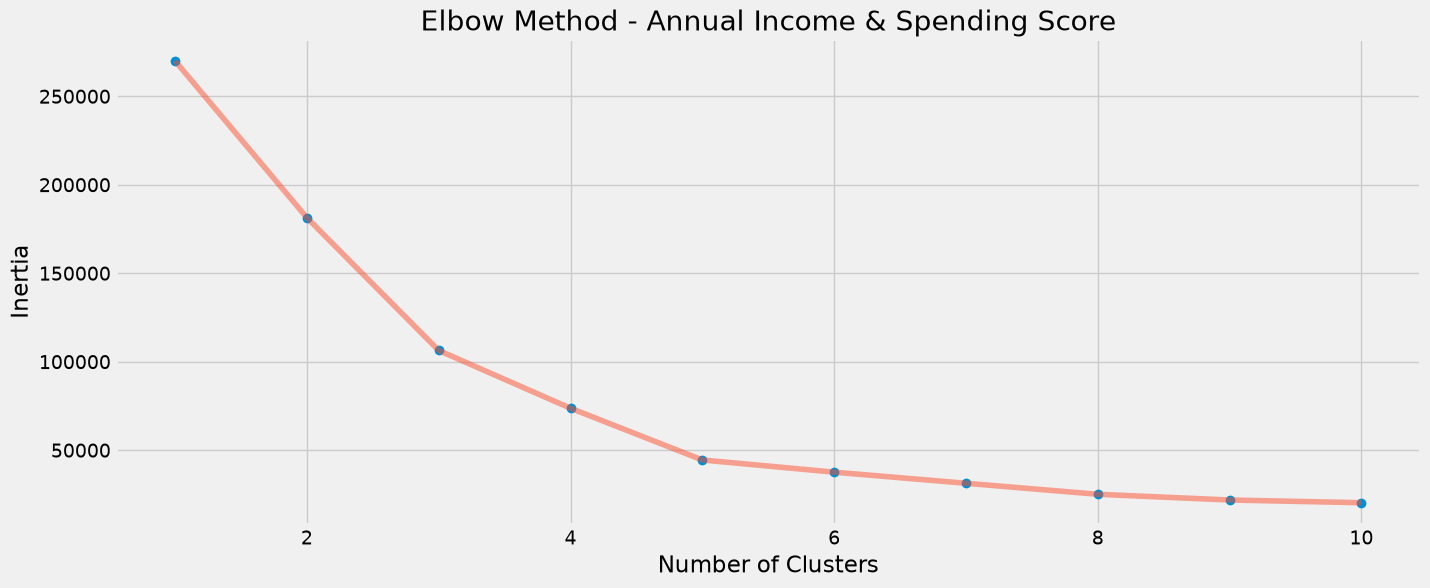

In [17]:
plt.figure(1, figsize = (15, 6))
plt.plot(np.arange(1 , 11), inertia, 'o')
plt.plot(np.arange(1 , 11), inertia, '-', alpha = 0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method - Annual Income & Spending Score')
plt.show()

Đặng Phan Duy - 6451071010

Nhận xét: inertia giảm mạnh đến k = 5, sau k = 5 đường cong giảm chậm lại rõ rệt. Vị trí khuỷu tay là k = 5 nên chọn số cụm k = 5.

In [18]:
algorithm = KMeans(n_clusters = 5, init='random', n_init=10, random_state=42)
algorithm.fit(X2)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_
print("Centroids:\n", centroids2)

Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]


Đặng Phan Duy - 6451071010

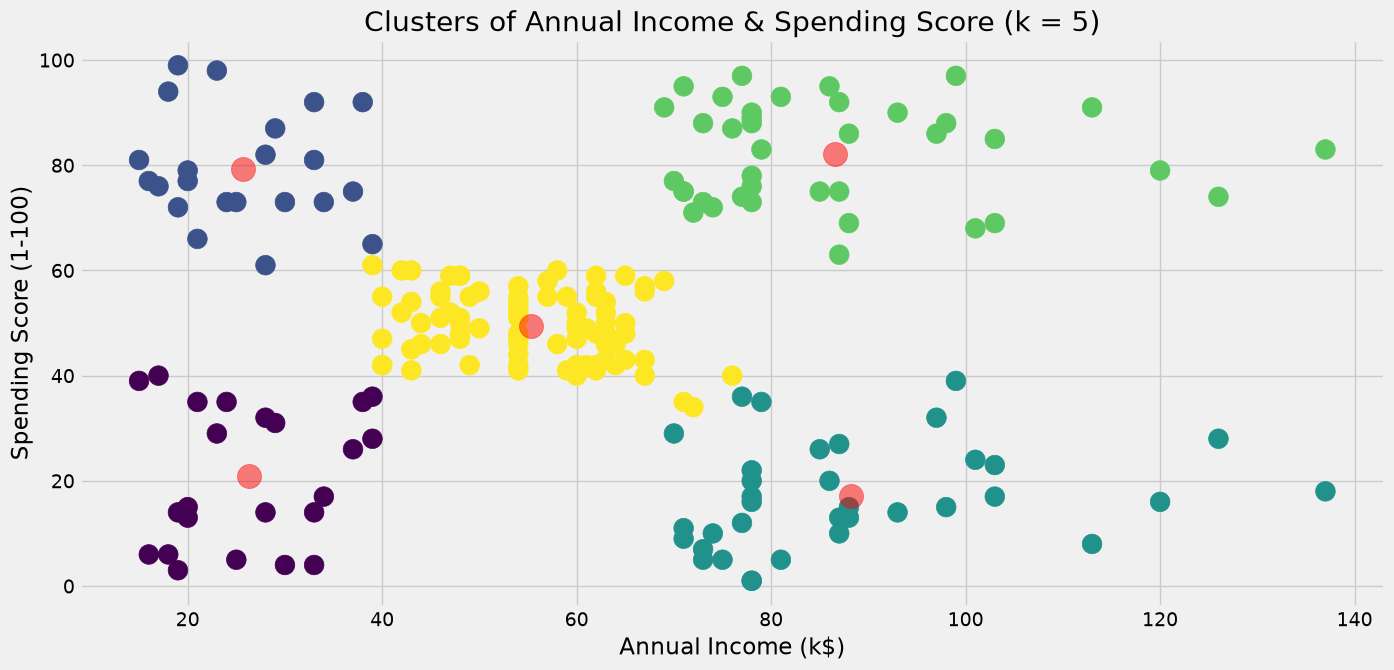

In [19]:
plt.figure(1 , figsize = (15, 7) )
plt.clf()
plt.scatter(x = 'Annual Income (k$)', y = 'Spending Score (1-100)', data = data, c = labels2,
            s = 200 )
plt.scatter(x = centroids2[: , 0], y =  centroids2[: , 1], s = 300, c = 'red', alpha = 0.5)
plt.ylabel('Spending Score (1-100)'), plt.xlabel('Annual Income (k$)')
plt.title('Clusters of Annual Income & Spending Score (k = 5)')
plt.show()

Đặng Phan Duy - 6451071010

In [20]:
silhouette2 = metrics.silhouette_score(X2, labels2, metric = 'euclidean')
print("Silhouette coefficient (Annual Income & Spending Score):", silhouette2)

Silhouette coefficient (Annual Income & Spending Score): 0.553931997444648


Đặng Phan Duy - 6451071010

### Gom cụm theo Tuổi, Thu nhập hằng năm và Số điểm mua sắm

In [21]:
X3 = data[['Age' , 'Annual Income (k$)' ,'Spending Score (1-100)']].iloc[: , :].values
inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters = n, init='random', n_init=10, random_state=42)
    algorithm.fit(X3)
    inertia.append(algorithm.inertia_)
print(np.round(inertia, 2))

[308812.78 212840.17 143342.75 104366.15  75350.78  58302.41  51116.99
  44309.84  40972.38  38652.17]


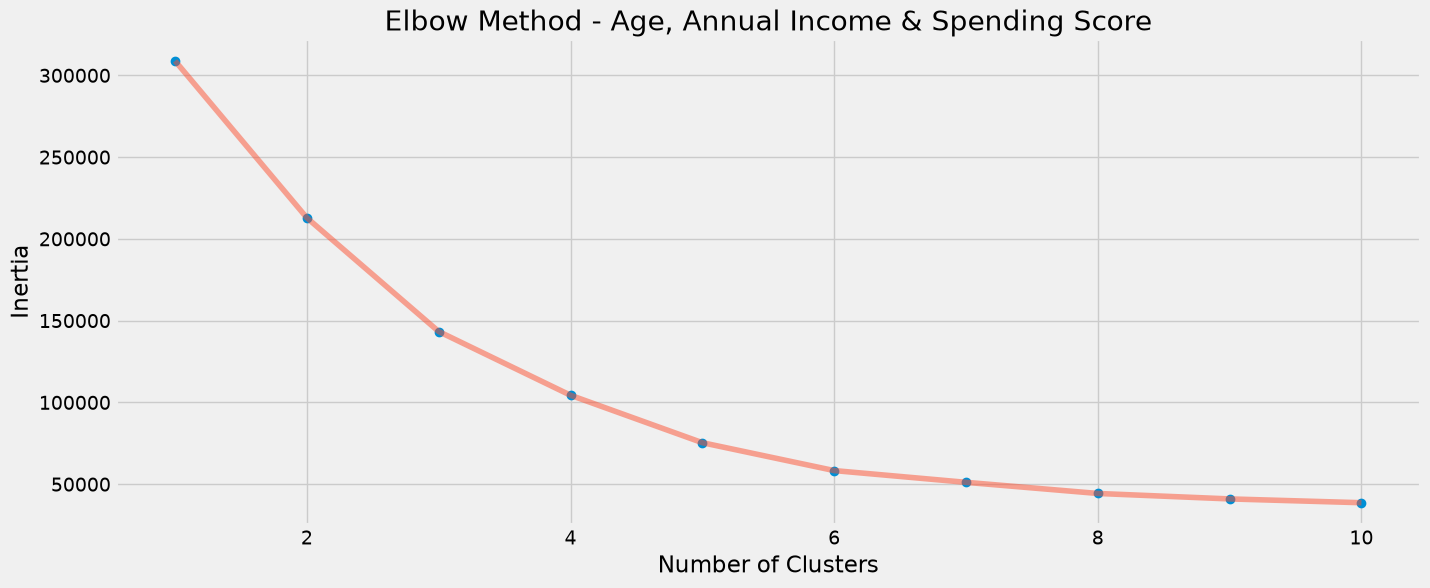

In [22]:
plt.figure(1, figsize = (15, 6))
plt.plot(np.arange(1 , 11), inertia, 'o')
plt.plot(np.arange(1 , 11), inertia, '-', alpha = 0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method - Age, Annual Income & Spending Score')
plt.show()

Đặng Phan Duy - 6451071010

Nhận xét: inertia giảm mạnh đến k = 6, từ k = 6 trở đi đường cong giảm chậm. Vị trí khuỷu tay là k = 6 nên chọn số cụm k = 6.

In [23]:
algorithm = KMeans(n_clusters = 6, init='random', n_init=10, random_state=42)
algorithm.fit(X3)
labels3 = algorithm.labels_
centroids3 = algorithm.cluster_centers_
print("Centroids:\n", centroids3)

Centroids:
 [[44.31818182 25.77272727 20.27272727]
 [32.69230769 86.53846154 82.12820513]
 [25.27272727 25.72727273 79.36363636]
 [27.         56.65789474 49.13157895]
 [41.68571429 88.22857143 17.28571429]
 [56.34090909 53.70454545 49.38636364]]


Đặng Phan Duy - 6451071010

In [24]:
data['label3'] =  labels3
trace1 = go.Scatter3d(
    x = data['Age'],
    y = data['Spending Score (1-100)'],
    z = data['Annual Income (k$)'],
    mode='markers',
     marker=dict(
        color = data['label3'],
        size= 20,
        line=dict(
            color= data['label3'],
            width= 12
        ),
        opacity=0.8
     )
)
dat = [trace1]
layout = go.Layout(
    title= 'Clusters',
    scene = dict(
            xaxis = dict(title  = 'Age'),
            yaxis = dict(title  = 'Spending Score'),
            zaxis = dict(title  = 'Annual Income')
        )
)
fig = go.Figure(data=dat, layout=layout)
py.offline.iplot(fig)

Đặng Phan Duy - 6451071010

In [25]:
silhouette3 = metrics.silhouette_score(X3, labels3, metric = 'euclidean')
print("Silhouette coefficient (Age, Annual Income & Spending Score):", silhouette3)

Silhouette coefficient (Age, Annual Income & Spending Score): 0.4523566166018854


Đặng Phan Duy - 6451071010

In [26]:
results = pd.DataFrame({
    'Thuộc tính gom cụm': ['Age & Spending Score', 'Annual Income & Spending Score', 'Age, Annual Income & Spending Score'],
    'Số cụm (k)': [4, 5, 6],
    'Silhouette coefficient': [silhouette1, silhouette2, silhouette3]
})
results

,Thuộc tính gom cụm,Số cụm (k),Silhouette coefficient
0,Age & Spending Score,4,0.499739
1,Annual Income & Spending Score,5,0.553932
2,"Age, Annual Income & Spending Score",6,0.452357


Đặng Phan Duy - 6451071010

Nhận xét:

- Gom cụm theo Thu nhập hằng năm và Số điểm mua sắm (k = 5) cho hệ số Silhouette cao nhất (≈ 0.55): 5 nhóm khách hàng tách biệt rõ trên biểu đồ (thu nhập thấp - chi tiêu thấp, thu nhập thấp - chi tiêu cao, thu nhập trung bình - chi tiêu trung bình, thu nhập cao - chi tiêu thấp, thu nhập cao - chi tiêu cao). Đây là cách phân nhóm có ý nghĩa nhất cho việc phân khúc khách hàng.
- Gom cụm theo Tuổi và Số điểm mua sắm (k = 4) đạt Silhouette ≈ 0.50, các cụm có phần chồng lấn ở vùng điểm mua sắm trung bình.
- Gom cụm theo cả 3 thuộc tính (k = 6) có Silhouette thấp nhất (≈ 0.45) do khi thêm chiều dữ liệu thì khoảng cách giữa các điểm trở nên kém phân biệt hơn, các cụm khó tách bạch hơn. Tuy vậy, kết quả 3D cho thấy các cụm vẫn tương ứng với các nhóm thu nhập - chi tiêu ở trường hợp 2, có thêm thông tin về độ tuổi.
- Lưu ý: dữ liệu chưa được chuẩn hóa nên thuộc tính có miền giá trị lớn hơn (Thu nhập: 15 - 137) ảnh hưởng đến khoảng cách nhiều hơn Tuổi (18 - 70).